<a href="https://colab.research.google.com/github/swathi9876/breast_cancer_detection_using_decentralization/blob/main/svmandlogistic_nonIID_federated.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [24]:
from google.colab import files

uploaded = files.upload()

Saving ank.csv to ank (6).csv


In [25]:
import torch
import torch.nn as nn
import torch.optim as optim
import pandas as pd
import numpy as np
from sklearn.preprocessing import LabelEncoder
import matplotlib.pyplot as plt

# Define the model
class SVMModel(nn.Module):
    def __init__(self, input_dim):
        super(SVMModel, self).__init__()
        self.linear = nn.Linear(input_dim, 1)

    def forward(self, x):
        return self.linear(x)

# Preprocess the dataset
def preprocess_data(data_path):
    # Load the dataset
    df = pd.read_csv(data_path)

    # Drop any rows with missing values
    df = df.dropna()

    # Label encoding for the "diagnosis" column
    label_encoder = LabelEncoder()
    df['diagnosis'] = label_encoder.fit_transform(df['diagnosis'])

    # Drop the first column
    df = df.drop(df.columns[0], axis=1)

    # Extract features and labels
    X = df.iloc[:, 1:].values  # Features (all columns except the first one)
    y = df.iloc[:, 0].values   # Labels (first column)

    return X, y

# Split data into clients with non-IID distribution
def split_data_non_iid(X, y, num_clients):
    unique_classes = np.unique(y)
    class_per_client = len(unique_classes) // num_clients

    client_data = []
    for i in range(num_clients):
        classes_for_client = unique_classes[i * class_per_client: (i + 1) * class_per_client]
        client_indices = []
        for cls in classes_for_client:
            cls_indices = np.where(y == cls)[0]
            client_indices.extend(cls_indices[:len(cls_indices) // num_clients])
        client_data.append((X[client_indices], y[client_indices]))

    return client_data

# Create a federated dataset
def create_federated_dataset(client_data):
    federated_data = []
    for X, y in client_data:
        federated_data.append({'X': torch.tensor(X, dtype=torch.float32),
                               'y': torch.tensor(y, dtype=torch.float32)})
    return federated_data

# Define the FedAvg algorithm
def federated_average(model, client_models):
    averaged_state_dict = {}
    for i, client_state_dict in enumerate(client_models):
        for key, value in client_state_dict.items():
            if i == 0:
                averaged_state_dict[key] = value.clone().detach()
            else:
                averaged_state_dict[key] += value.clone().detach()
    for key in averaged_state_dict:
        averaged_state_dict[key] /= len(client_models)
    return averaged_state_dict
def fedprox(model, client_models):
    averaged_state_dict = {}
    for i, client_state_dict in enumerate(client_models):
        for key, value in client_state_dict.items():
            if i == 0:
                averaged_state_dict[key] = value.clone().detach()
            else:
                averaged_state_dict[key] += value.clone().detach()
    for key in averaged_state_dict:
        averaged_state_dict[key] /= len(client_models)
    return averaged_state_dict



fed avg using svm non iid

Number of clients: 11
Round 1, Accuracy: 0.6274164915084839
Round 2, Accuracy: 0.3725834786891937
Round 3, Accuracy: 0.6274164915084839
Round 4, Accuracy: 0.365553617477417
Round 5, Accuracy: 0.3725834786891937
Round 6, Accuracy: 0.6309314370155334
Round 7, Accuracy: 0.37082600593566895
Round 8, Accuracy: 0.6274164915084839
Round 9, Accuracy: 0.3725834786891937
Round 10, Accuracy: 0.3725834786891937
Number of clients: 12
Round 1, Accuracy: 0.6274164915084839
Round 2, Accuracy: 0.49384886026382446
Round 3, Accuracy: 0.6274164915084839
Round 4, Accuracy: 0.17926186323165894
Round 5, Accuracy: 0.3725834786891937
Round 6, Accuracy: 0.6274164915084839
Round 7, Accuracy: 0.6274164915084839
Round 8, Accuracy: 0.6274164915084839
Round 9, Accuracy: 0.6274164915084839
Round 10, Accuracy: 0.6274164915084839
Number of clients: 13
Round 1, Accuracy: 0.3567662537097931
Round 2, Accuracy: 0.6274164915084839
Round 3, Accuracy: 0.3725834786891937
Round 4, Accuracy: 0.6379613280296326
Round 5, Accuracy:

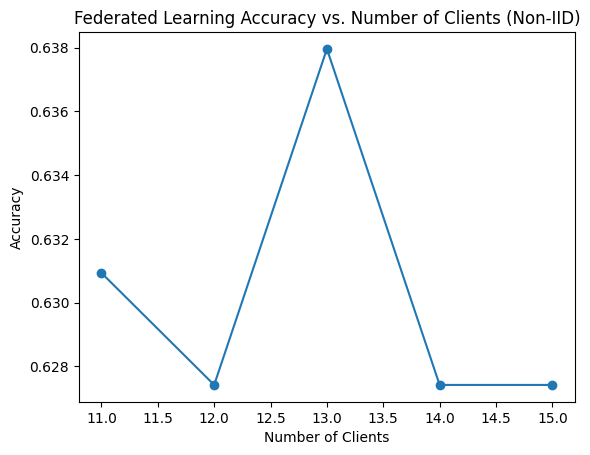

In [26]:

# Main function
def main():
    num_rounds = 10
    input_dim = 30  # Adjust based on your dataset

    # Preprocess the dataset
    X, y = preprocess_data("ank.csv")

    cl, acc = [], []
    for i in range(11, 16):
        client_data = split_data_non_iid(X, y, i)
        print("Number of clients:", i)
        federated_data = create_federated_dataset(client_data)
        cl.append(i)
        max_acc = 0

        model = SVMModel(input_dim)

        for round in range(num_rounds):
            client_models = []
            for client_data in federated_data:
                local_model = SVMModel(input_dim)
                optimizer = optim.SGD(local_model.parameters(), lr=0.01)
                criterion = nn.HingeEmbeddingLoss()

                # Training
                for epoch in range(10):  # 10 epochs
                    optimizer.zero_grad()
                    outputs = local_model(client_data['X'])
                    loss = criterion(outputs.squeeze(), client_data['y'])
                    loss.backward()
                    optimizer.step()

                client_models.append(local_model.state_dict())

            # Perform federated averaging
            averaged_state_dict = federated_average(model, client_models)
            model.load_state_dict(averaged_state_dict)

            # Calculate accuracy
            with torch.no_grad():
                outputs = model(torch.tensor(X, dtype=torch.float32))
                predicted = (outputs.squeeze() > 0).float()
                accuracy = (predicted == torch.tensor(y, dtype=torch.float32)).float().mean().item()
                if accuracy > max_acc:
                    max_acc = accuracy

            print(f'Round {round+1}, Accuracy: {accuracy}')

        acc.append(max_acc)

    # Plotting
    plt.plot(cl, acc, marker='o')
    plt.xlabel('Number of Clients')
    plt.ylabel('Accuracy')
    plt.title('Federated Learning Accuracy vs. Number of Clients (Non-IID)')
    plt.show()

if __name__ == "__main__":
    main()

fed prox svm non iid

Number of clients: 11
Round 1, Accuracy: 0.6274164915084839
Round 2, Accuracy: 0.6274164915084839
Round 3, Accuracy: 0.6274164915084839
Round 4, Accuracy: 0.6274164915084839
Round 5, Accuracy: 0.6274164915084839
Round 6, Accuracy: 0.6274164915084839
Round 7, Accuracy: 0.6274164915084839
Round 8, Accuracy: 0.6274164915084839
Round 9, Accuracy: 0.6274164915084839
Round 10, Accuracy: 0.6274164915084839
Number of clients: 12
Round 1, Accuracy: 0.6274164915084839
Round 2, Accuracy: 0.6274164915084839
Round 3, Accuracy: 0.6274164915084839
Round 4, Accuracy: 0.6274164915084839
Round 5, Accuracy: 0.6274164915084839
Round 6, Accuracy: 0.6274164915084839
Round 7, Accuracy: 0.6274164915084839
Round 8, Accuracy: 0.6274164915084839
Round 9, Accuracy: 0.6274164915084839
Round 10, Accuracy: 0.6274164915084839
Number of clients: 13
Round 1, Accuracy: 0.6274164915084839
Round 2, Accuracy: 0.6274164915084839
Round 3, Accuracy: 0.6274164915084839
Round 4, Accuracy: 0.6274164915084839
Round 5, Accuracy: 0

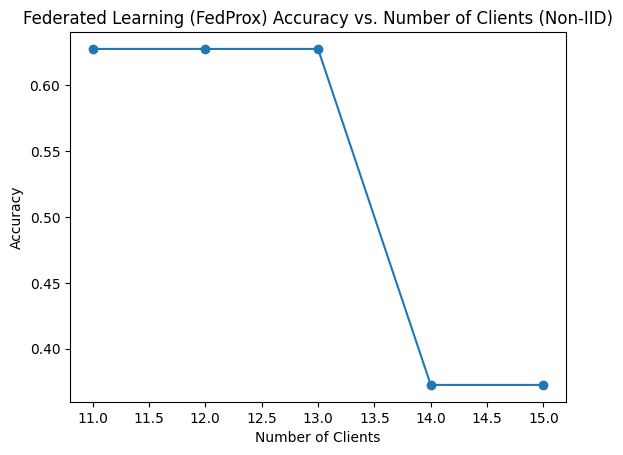

In [27]:



# Main function
def main():
    num_rounds = 10
    input_dim = 30  # Adjust based on your dataset
    mu = 0.01       # FedProx regularization parameter

    # Preprocess the dataset
    X, y = preprocess_data("ank.csv")

    cl, acc = [], []
    for i in range(11, 16):
        client_data = split_data_non_iid(X, y, i)
        print("Number of clients:", i)
        federated_data = create_federated_dataset(client_data)
        cl.append(i)
        max_acc = 0

        model = SVMModel(input_dim)

        for round in range(num_rounds):
            client_models = []
            # Save global model snapshot for proximal term
            global_model_copy = copy.deepcopy(model)

            for client_data in federated_data:
                local_model = SVMModel(input_dim)
                # Each client starts training from the current global model weights
                local_model.load_state_dict(model.state_dict())
                optimizer = optim.SGD(local_model.parameters(), lr=0.01)
                criterion = nn.HingeEmbeddingLoss()

                # Training
                for epoch in range(10):  # 10 epochs
                    optimizer.zero_grad()
                    outputs = local_model(client_data['X'])
                    loss = criterion(outputs.squeeze(), client_data['y'])

                    # Calculate the L2 proximal term
                    proximal_term = 0.0
                    for local_param, global_param in zip(local_model.parameters(), global_model_copy.parameters()):
                        proximal_term += torch.sum((local_param - global_param.detach()) ** 2)

                    # Add the FedProx proximal penalty to the loss
                    loss = loss + (mu / 2) * proximal_term
                    loss.backward()
                    optimizer.step()

                client_models.append(local_model.state_dict())

            # Perform federated averaging (using renamed fedprox function)
            averaged_state_dict = fedprox(model, client_models)
            model.load_state_dict(averaged_state_dict)

            # Calculate accuracy
            with torch.no_grad():
                outputs = model(torch.tensor(X, dtype=torch.float32))
                predicted = (outputs.squeeze() > 0).float()
                accuracy = (predicted == torch.tensor(y, dtype=torch.float32)).float().mean().item()
                if accuracy > max_acc:
                    max_acc = accuracy

            print(f'Round {round+1}, Accuracy: {accuracy}')

        acc.append(max_acc)

    # Plotting
    plt.plot(cl, acc, marker='o')
    plt.xlabel('Number of Clients')
    plt.ylabel('Accuracy')
    plt.title('Federated Learning (FedProx) Accuracy vs. Number of Clients (Non-IID)')
    plt.show()

if __name__ == "__main__":
    main()

Prepocessing the dataset

definig the fed prox and fed avg function

fed prox plotting svm non iid

# logistic regression

In [28]:
# Define the Logistic Regression model
class LogisticRegression(nn.Module):
    def __init__(self, input_dim, output_dim):
        super(LogisticRegression, self).__init__()
        self.linear = nn.Linear(input_dim, output_dim)

    def forward(self, x):
        out = self.linear(x)
        return out

Number of clients: 11
Round 1, Accuracy: 0.0
Round 2, Accuracy: 0.0
Round 3, Accuracy: 0.0
Round 4, Accuracy: 0.0
Round 5, Accuracy: 0.0
Round 6, Accuracy: 0.0
Round 7, Accuracy: 0.0
Round 8, Accuracy: 0.0
Round 9, Accuracy: 0.0
Round 10, Accuracy: 0.0
Number of clients: 12
Round 1, Accuracy: 0.0
Round 2, Accuracy: 0.0
Round 3, Accuracy: 0.0
Round 4, Accuracy: 0.0
Round 5, Accuracy: 0.0
Round 6, Accuracy: 0.0
Round 7, Accuracy: 0.0
Round 8, Accuracy: 0.0
Round 9, Accuracy: 0.0
Round 10, Accuracy: 0.0
Number of clients: 13
Round 1, Accuracy: 0.6906853914260864
Round 2, Accuracy: 0.6906853914260864
Round 3, Accuracy: 0.6906853914260864
Round 4, Accuracy: 0.6906853914260864
Round 5, Accuracy: 0.6906853914260864
Round 6, Accuracy: 0.6906853914260864
Round 7, Accuracy: 0.6906853914260864
Round 8, Accuracy: 0.6906853914260864
Round 9, Accuracy: 0.6906853914260864
Round 10, Accuracy: 0.6906853914260864
Number of clients: 14
Round 1, Accuracy: 0.0
Round 2, Accuracy: 0.0
Round 3, Accuracy: 0.0


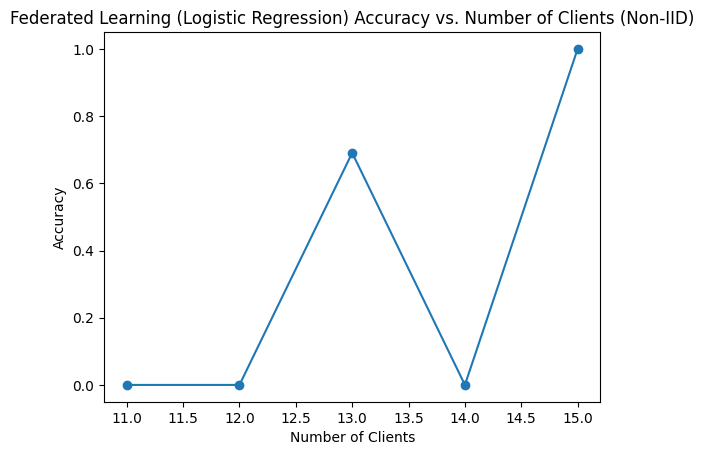

In [29]:
# Main function adapted for Logistic Regression
def main():
    num_rounds = 10
    input_dim = 30  # Adjust based on your dataset
    output_dim = 2  # Binary classification

    # Preprocess the dataset

    X, y = preprocess_data("ank.csv")
    y = np.where(y == -1.0, 0, 1).astype(np.int64)

    cl, acc = [], []
    for i in range(11, 16):
        client_data = split_data_non_iid(X, y, i)
        print("Number of clients:", i)
        federated_data = []
        for X_c, y_c in client_data:
            federated_data.append({
                'X': torch.tensor(X_c, dtype=torch.float32),
                'y': torch.tensor(y_c, dtype=torch.long) # Use long for CrossEntropyLoss
            })

        cl.append(i)
        max_acc = 0

        model = LogisticRegression(input_dim, output_dim)

        for round in range(num_rounds):
            client_models = []
            for client_data in federated_data:
                local_model = LogisticRegression(input_dim, output_dim)
                local_model.load_state_dict(model.state_dict())
                optimizer = optim.SGD(local_model.parameters(), lr=0.01)
                criterion = nn.CrossEntropyLoss()

                # Training
                for epoch in range(10):  # 10 epochs
                    optimizer.zero_grad()
                    outputs = local_model(client_data['X'])
                    loss = criterion(outputs, client_data['y'])
                    loss.backward()
                    optimizer.step()

                client_models.append(local_model.state_dict())

            # Perform federated averaging
            averaged_state_dict = federated_average(model, client_models)
            model.load_state_dict(averaged_state_dict)

            # Calculate accuracy
            with torch.no_grad():
                outputs = model(torch.tensor(X, dtype=torch.float32))
                _, predicted = torch.max(outputs, 1)
                accuracy = (predicted == torch.tensor(y, dtype=torch.long)).float().mean().item()
                if accuracy > max_acc:
                    max_acc = accuracy

            print(f'Round {round+1}, Accuracy: {accuracy}')

        acc.append(max_acc)

    # Plotting
    plt.plot(cl, acc, marker='o')
    plt.xlabel('Number of Clients')
    plt.ylabel('Accuracy')
    plt.title('Federated Learning (Logistic Regression) Accuracy vs. Number of Clients (Non-IID)')
    plt.show()

if __name__ == "__main__":
    main()

Number of clients: 11
Round 1, Accuracy: 0.0
Round 2, Accuracy: 0.0
Round 3, Accuracy: 0.0
Round 4, Accuracy: 0.0
Round 5, Accuracy: 0.0
Round 6, Accuracy: 0.0
Round 7, Accuracy: 0.0
Round 8, Accuracy: 0.0
Round 9, Accuracy: 0.0
Round 10, Accuracy: 0.0
Number of clients: 12
Round 1, Accuracy: 1.0
Round 2, Accuracy: 1.0
Round 3, Accuracy: 1.0
Round 4, Accuracy: 1.0
Round 5, Accuracy: 1.0
Round 6, Accuracy: 1.0
Round 7, Accuracy: 1.0
Round 8, Accuracy: 1.0
Round 9, Accuracy: 1.0
Round 10, Accuracy: 1.0
Number of clients: 13
Round 1, Accuracy: 0.0
Round 2, Accuracy: 0.0
Round 3, Accuracy: 0.0
Round 4, Accuracy: 0.0
Round 5, Accuracy: 0.0
Round 6, Accuracy: 0.0
Round 7, Accuracy: 0.0
Round 8, Accuracy: 0.0
Round 9, Accuracy: 0.0
Round 10, Accuracy: 0.0
Number of clients: 14
Round 1, Accuracy: 0.44815465807914734
Round 2, Accuracy: 0.44815465807914734
Round 3, Accuracy: 0.44815465807914734
Round 4, Accuracy: 0.44815465807914734
Round 5, Accuracy: 0.44815465807914734
Round 6, Accuracy: 0.448

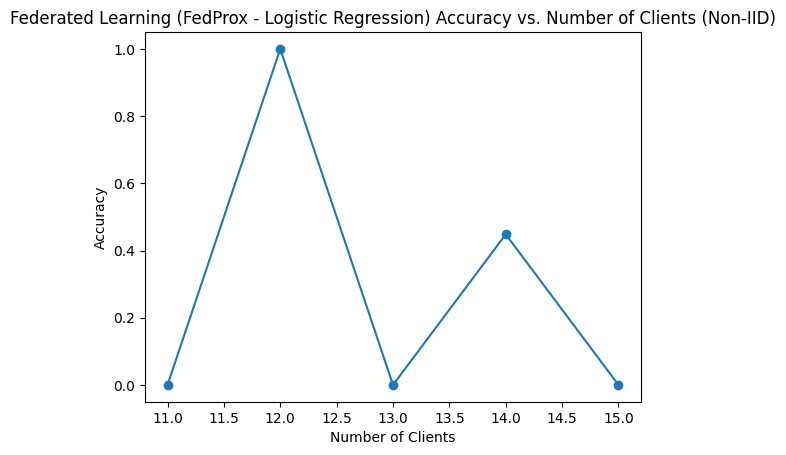

In [30]:
def main():
    num_rounds = 10
    input_dim = 30  # Adjust based on your dataset
    output_dim = 2  # Binary classification
    mu = 0.01       # FedProx regularization parameter

    # Preprocess the dataset
    X, y = preprocess_data("ank.csv")
    # Convert labels from -1/+1 back to 0/1 for CrossEntropyLoss
    y = np.where(y == -1.0, 0, 1).astype(np.int64)

    cl, acc = [], []
    for i in range(11, 16):
        client_data = split_data_non_iid(X, y, i)
        print("Number of clients:", i)

        # Prepare client tensors with correct data types
        federated_data = []
        for X_c, y_c in client_data:
            federated_data.append({
                'X': torch.tensor(X_c, dtype=torch.float32),
                'y': torch.tensor(y_c, dtype=torch.long)
            })

        cl.append(i)
        max_acc = 0

        model = LogisticRegression(input_dim, output_dim)

        for round in range(num_rounds):
            client_models = []
            # Save global model snapshot for proximal term
            global_model_copy = copy.deepcopy(model)

            for client_data in federated_data:
                local_model = LogisticRegression(input_dim, output_dim)
                # Each client starts training from the current global model weights
                local_model.load_state_dict(model.state_dict())
                optimizer = optim.SGD(local_model.parameters(), lr=0.01)
                criterion = nn.CrossEntropyLoss()

                # Training
                for epoch in range(10):  # 10 epochs
                    optimizer.zero_grad()
                    outputs = local_model(client_data['X'])
                    loss = criterion(outputs, client_data['y'])

                    # Calculate the L2 proximal term
                    proximal_term = 0.0
                    for local_param, global_param in zip(local_model.parameters(), global_model_copy.parameters()):
                        proximal_term += torch.sum((local_param - global_param.detach()) ** 2)

                    # Add the FedProx proximal penalty to the loss
                    loss = loss + (mu / 2) * proximal_term
                    loss.backward()
                    optimizer.step()

                client_models.append(local_model.state_dict())

            # Perform federated aggregation using the fedprox routine
            averaged_state_dict = fedprox(model, client_models)
            model.load_state_dict(averaged_state_dict)

            # Calculate accuracy
            with torch.no_grad():
                outputs = model(torch.tensor(X, dtype=torch.float32))
                _, predicted = torch.max(outputs, 1)
                accuracy = (predicted == torch.tensor(y, dtype=torch.long)).float().mean().item()
                if accuracy > max_acc:
                    max_acc = accuracy

            print(f'Round {round+1}, Accuracy: {accuracy}')

        acc.append(max_acc)

    # Plotting
    plt.plot(cl, acc, marker='o')
    plt.xlabel('Number of Clients')
    plt.ylabel('Accuracy')
    plt.title('Federated Learning (FedProx - Logistic Regression) Accuracy vs. Number of Clients (Non-IID)')
    plt.show()

if __name__ == "__main__":
    main()